# Analysis Capsule notebook
This is a working notebook for generating data analysis capsules for the FutureHouse Evals team. You'll find instructions for how to use this notebook below.

If you are not familiar with Colab Notebooks, please visit the welcome notebook at: https://colab.research.google.com/notebooks/intro.ipynb. In short, they function similarly to standard Jupyter Notebooks, but are more shareable for our purpose.

## Instructions – IMPORTANT, READ CAREFULLY
This notebook has been created for your specific use, and you should work directly in it. *DO NOT* download the notebook and work locally and reupload.

All cells of the notebook should be run in the place and left as-is so outputs can be inspected.

You may write code in either `Python` or `R`, as well as use terminal commands. The default is `Python`, but you may use `R` on a cell-by-cell basis using the code example–see below.

Please be highly verbose using markdown cells to outline the high-level steps taken including rationale behind decisions made for using various tools or carrying out specific steps. You should use inline comments diligenty to explain each code block's purpose.

It is also helpful if you are liberal in your use of separate code cells rather than including too much code together in a single cell.

You may import external packages at the top or load them throughout the code. Feel free to do so in whichever way is most natural to you.

Please take time to carefully review the examples for an indication of how to follow these instructions.

### File handling
Local input files can be uploaded by clicking on the folder icon on the left. These are stored in a `/content/` directory. They can be programmatically accessed simply with the filename.

Output files you write are also written to the `/content/` directory. You can view this directory at any time by clicking the folder icon.

*IMPORTANT NOTES*:
1. Any files you upload as input data *MUST ALSO* be uploaded to the same google drive folder that this notebook is contained in.
2. *DO NOT* use any google docs in your analysis (e.g. csv files turned into google sheets.) Use the original csv, txt, etc.

### If using R, read below. Otherwise skip to [Code](#scrollTo=CK_xKRknfCxI)

If your entire notebook will be `R`, you can change the notebook runtime in the Runtime tab above (Runtime -> Change runtime type).

If you will be using `R` in only part of your analysis, you can run individual cells with R using the the steps below:

*   Run the cell below first to load the rmagic extension.
*   You can then include `%%R` at the top of any cell to run it as `R` code rather than `Python`.



In [ ]:
## loading rmagic to enable R
## to use R in an individual cell, put %%R at the top
%load_ext rpy2.ipython

In [ ]:
## Example of individual R code cell

%%R      ## put this at the top of a cell to run R code inside it
x <- 42
print(x)

[1] 42



---
As always, if you have any questions do not hesitate to reach out to Jon via Slack or email (jon@futurehouse.org)

```
## Template version 4.0
```




---



# Your capsule begins here

Your analysis will be carried out below. Note there are four separate sections for Data loading, Data exploration, Analysis code, and Results. Please **read section-specific instructions carefully.**

# Hypothesis setup

**Hypothesis:** Tubercolosis BCG re-vaccination reduces COVID-19 disease severity among healthcare workers

**Aim:** Confirm there is statistically significant correlation between disease severity and BCG re-vaccination among healthcare workers

- Zenodo data: https://zenodo.org/records/12737228

The data are coming from a Ph3 trial and they are mostly clinical metadata.

I have uploaded the individual csv files in the respective drive as well here: https://drive.google.com/drive/folders/1Zvj8aRE1XaZAKea4fBoFI47Llbzn9pFQ


### Data loading

Load any local or remote data in this section.

For each data file or set of related files, include a brief description as a comment above or at the end of the loading call.

In [ ]:
## Load data here

I have uploaded the individual csv files in the respective drive as well here: https://drive.google.com/drive/folders/1Zvj8aRE1XaZAKea4fBoFI47Llbzn9pFQ

The codes for the data in each csv file are below:

AE - Adverse Events

CM - Concomitant Medication

DM - Demographics

DS - Disposition

EX - Exposure

IE - Inclusion and Exclusion Criteria

LB - Laboratory Findings

MH - Medical History

SV - Subject Visits

VS - Vital Signs

In [1]:
# importing and installing some modules to work with
import os, sys

import pandas as pd
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_colwidth', 100)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu
from statsmodels.miscmodels.ordinal_model import OrderedModel
from sklearn.preprocessing import LabelEncoder

In [4]:
# these are the adverse effects dataframe
ae_data = pd.read_csv("https://docs.google.com/spreadsheets/d/1bMgEPfhXMOmqX0XMnbkzTRK0_URsXRF_hFA08C7gAqM/export?format=csv")
ae_data

,STUDYID,TRTGRP,USUBJID,AESPID,AECAT,AEPT,AEPTCD,AEHLGT,AEHLGTCD,AEHLT,AEHLTCD,AELLT,AELLTCD,AESTDTC,AEENDTC,AEENDTFU,AEOUT,AEOUTFU,AEONGO,AESEV,AEHS,AEHSFU,AESER,AESERCRIT,AEDEATH,AEREL,AEREPDT,AEFUDT1,AEFUDT2,AEFUDT3,OnsetHS,AEWK1HS,AEWK2HS,AEWK3HS,AEWK4HS,AEWK5HS,AEWK6HS,AEWK7HS,AEWK8HS,AEWK9HS,AEWK10HS,AEWK11HS,AEWK12HS,AE_ISR_LYMPH,AE_ISR_PAIN,AE_ISR_RED,AE_ISR_SWELLING,AE_ISR_CM,AE_ISR_ULCER,AESOC,AESOCCD
0,TASK008-BCG CORONA,Placebo,BCG0001,1.0,RTI,Cough,10011224.0,Respiratory disorders NEC,10038716.0,Coughing and associated symptoms,10011233.0,Cough,10011224.0,16.0,19.0,NaN,Resolved,NaN,No,NaN,1.0,NaN,No,NaN,NaN,Unrelated,21.0,NaN,NaN,NaN,1,1,N_A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Respiratory, thoracic and mediastinal disorders",10038738.0
1,TASK008-BCG CORONA,Placebo,BCG0002,1.0,RTI,Acute sinusitis,10001076.0,Infections - pathogen unspecified,10021879.0,Upper respiratory tract infections,10046309.0,Acute sinusitis,10001076.0,269.0,NaN,305.0,Improved,Resolved,Yes,2.0,2.0,2.0,No,NaN,NaN,Unrelated,295.0,296.0,303.0,311.0,2,2,2,2.0,2.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Infections and infestations,10021881.0
2,TASK008-BCG CORONA,Placebo,BCG0002,2.0,Other,Asthma,10003553.0,Bronchial disorders (excl neoplasms),10006436.0,Bronchospasm and obstruction,10006484.0,Exacerbation of asthma,10015575.0,269.0,NaN,303.0,Improved,Resolved,Yes,2.0,2.0,1.0,No,NaN,NaN,Unrrelated,295.0,303.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Respiratory, thoracic and mediastinal disorders",10038738.0
3,TASK008-BCG CORONA,Placebo,BCG0002,3.0,Other,Adverse drug reaction,10061623.0,Therapeutic and nontherapeutic effects (excl toxicity),10062915.0,Therapeutic and nontherapeutic responses,10043409.0,Adverse reaction to antibiotics,10080920.0,284.0,292.0,NaN,Resolved,NaN,No,2.0,2.0,NaN,No,NaN,NaN,Unrrelated,295.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,General disorders and administration site conditions,10018065.0
4,TASK008-BCG CORONA,Placebo,BCG0003,1.0,RTI,COVID-19,10084268.0,Viral infectious disorders,10047438.0,Coronavirus infectious,10084510.0,COVID-19,10084268.0,257.0,NaN,265.0,Unchanged,Resolved,Yes,1.0,1.0,1.0,No,NaN,NaN,Unrelated,259.0,267.0,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Infections and infestations,10021881.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2689,TASK008-BCG CORONA,Placebo,BCG5499,4.0,Other,Peripheral swelling,10048959.0,General system disorders NEC,10018073.0,General signs and symptoms NEC,10018072.0,Unilateral leg swelling,10080818.0,356.0,362.0,NaN,Resolved,NaN,No,2.0,2.0,NaN,No,NaN,NaN,Unrrelated,365.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,General disorders and administration site conditions,10018065.0
2690,TASK008-BCG CORONA,BCG,BCG5500,1.0,ISR,Injection site reaction,10022095.0,Administration site reactions,10001316.0,Injection site reactions,10022097.0,Injection site reaction,10022095.0,0.0,NaN,141.0,Improved,Resolved_,Yes,1.0,1.0,1.0,NaN,NaN,NaN,Definitely,27.0,56.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,Yes,Yes,Yes,No,No,General disorders and administration site conditions,10018065.0
2691,TASK008-BCG CORONA,BCG,BCG5500,2.0,Other,Type 2 diabetes mellitus,10067585.0,Glucose metabolism disorders (incl diabetes mellitus),10018424.0,Diabetes mellitus (incl subtypes),10012602.0,Type II diabetes mellitus,10045242.0,28.0,NaN,NaN,Improved,Improved,Yes,2.0,2.0,2.0,No,NaN,NaN,Unrrelated,56.0,357.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Metabolism and nutrition disorders,10027433.0
2692,TASK008-BCG CORONA,BCG,BCG5500,3.0,RTI,Upper respiratory tract infection,10046306.0,I

In [ ]:
# this dataframe contains information on
ae_data = pd.read_csv("https://docs.google.com/spreadsheets/d/1bMgEPfhXMOmqX0XMnbkzTRK0_URsXRF_hFA08C7gAqM/export?format=csv")
ae_data

In [7]:
# this dataframe contains information on whenther a worker has frequent contact with patients and with how many patients
# that is relevant for our hypothesis as a worker who doesn't have contact with patients is not useful to calculate statistical correlation with disease severity
# because the risk of contacting the disease again after vaccination or not is low so we will use these data downstream
dm_data = pd.read_csv("https://docs.google.com/spreadsheets/d/1z4J5pkNAhuZxepkScyQ0c7-G1LQNKJ5kS5xz00WKvVQ/export?format=csv")
dm_data

,STUDYID,TRTGRP,USUBJID,VISITNAM,SEX,Age,RACE,education,work_hours,patients_seen,expect_interact
0,TASK008-BCG CORONA,Placebo,BCG0001,Screening-Day -3 to 1,2,30-39,1,1,41-80,1-50,Yes
1,TASK008-BCG CORONA,Placebo,BCG0002,Screening-Day -3 to 1,2,40-49,2,1,1-40,1-50,No
2,TASK008-BCG CORONA,Placebo,BCG0003,Screening-Day -3 to 1,1,20-29,2,1,41-80,1-50,Yes
3,TASK008-BCG CORONA,Placebo,BCG0004,Screening-Day -3 to 1,1,40-49,2,1,41-80,1-50,Yes
4,TASK008-BCG CORONA,BCG,BCG0005,Screening-Day -3 to 1,1,30-39,2,1,41-80,1-50,Yes
...,...,...,...,...,...,...,...,...,...,...,...
995,TASK008-BCG CORONA,Placebo,BCG5496,Screening-Day -3 to 1,2,40-49,3,1,1-40,1-50,No
996,TASK008-BCG CORONA,Placebo,BCG5497,Screening-Day -3 to 1,2,60-69,1,2,1-40,1-50,No
997,TASK008-BCG CORONA,BCG,BCG5498,Screening-Day -3 to 1,2,50-59,1,2,1-40,1-50,No
998,TASK008-BCG CORONA,Placebo,BCG5499,Screening-Day -3 to 1,2,30-39,1,1,1-40,1-50,No


### Data exploration

Include data exploration here, including reading the structure of the data files such as column names, sample ID formats, etc.

In [ ]:
## Explore data here

In [5]:
# there is a lot of information in the ae_data dataframe but we only need a few columns for our analysis so let's filter them out
# AESEV --> the AE Severity
# AEHS --> the AE Highest Score (in case the AESEV is incomplete)
# TRTGRP --> the Treatment group (Placebo or BCG)
# USUBJID --> the patient ID

# since there are multiple values in the AESEV and AEHS columns for each patient I am taking the max value for severity
ae_data_clean = ae_data[['STUDYID', 'TRTGRP', 'USUBJID','AESEV','AEHS']].drop_duplicates().groupby('USUBJID').max().reset_index()

In [6]:
ae_data_clean

,USUBJID,STUDYID,TRTGRP,AESEV,AEHS
0,BCG0001,TASK008-BCG CORONA,Placebo,NaN,1.0
1,BCG0002,TASK008-BCG CORONA,Placebo,2.0,2.0
2,BCG0003,TASK008-BCG CORONA,Placebo,1.0,1.0
3,BCG0004,TASK008-BCG CORONA,Placebo,1.0,1.0
4,BCG0005,TASK008-BCG CORONA,BCG,2.0,2.0
...,...,...,...,...,...
995,BCG5496,TASK008-BCG CORONA,Placebo,2.0,2.0
996,BCG5497,TASK008-BCG CORONA,Placebo,2.0,2.0
997,BCG5498,TASK008-BCG CORONA,BCG,2.0,2.0
998,BCG5499,TASK008-BCG CORONA,Placebo,2.0,2.0


In [8]:
dm_data.patients_seen.unique()

# there are 3 groups of the number of patients seen by each worker

array(['1-50', '51-100', '>100'], dtype=object)

In [9]:
dm_data.expect_interact.unique()

# there is binary information on whether a worker is expected to interact with patients or not

array(['Yes', 'No'], dtype=object)

In [10]:
# bringing everything together in one dataframe
ae_dm_data = pd.merge(ae_data_clean,dm_data[['USUBJID','patients_seen','expect_interact']])

In [11]:
ae_dm_data

,USUBJID,STUDYID,TRTGRP,AESEV,AEHS,patients_seen,expect_interact
0,BCG0001,TASK008-BCG CORONA,Placebo,NaN,1.0,1-50,Yes
1,BCG0002,TASK008-BCG CORONA,Placebo,2.0,2.0,1-50,No
2,BCG0003,TASK008-BCG CORONA,Placebo,1.0,1.0,1-50,Yes
3,BCG0004,TASK008-BCG CORONA,Placebo,1.0,1.0,1-50,Yes
4,BCG0005,TASK008-BCG CORONA,BCG,2.0,2.0,1-50,Yes
...,...,...,...,...,...,...,...
995,BCG5496,TASK008-BCG CORONA,Placebo,2.0,2.0,1-50,No
996,BCG5497,TASK008-BCG CORONA,Placebo,2.0,2.0,1-50,No
997,BCG5498,TASK008-BCG CORONA,BCG,2.0,2.0,1-50,No
998,BCG5499,TASK008-BCG CORONA,Placebo,2.0,2.0,1-50,No


In [12]:
# checking for empty values
print(ae_dm_data.isnull().sum())

USUBJID              0
STUDYID              0
TRTGRP               0
AESEV              209
AEHS               143
patients_seen        0
expect_interact      0
dtype: int64


In [13]:
# there are some values missing from the AESEV column so let's drop those
full_data = ae_dm_data.dropna()

In [14]:
full_data

,USUBJID,STUDYID,TRTGRP,AESEV,AEHS,patients_seen,expect_interact
1,BCG0002,TASK008-BCG CORONA,Placebo,2.0,2.0,1-50,No
2,BCG0003,TASK008-BCG CORONA,Placebo,1.0,1.0,1-50,Yes
3,BCG0004,TASK008-BCG CORONA,Placebo,1.0,1.0,1-50,Yes
4,BCG0005,TASK008-BCG CORONA,BCG,2.0,2.0,1-50,Yes
5,BCG0006,TASK008-BCG CORONA,Placebo,1.0,2.0,1-50,Yes
...,...,...,...,...,...,...,...
995,BCG5496,TASK008-BCG CORONA,Placebo,2.0,2.0,1-50,No
996,BCG5497,TASK008-BCG CORONA,Placebo,2.0,2.0,1-50,No
997,BCG5498,TASK008-BCG CORONA,BCG,2.0,2.0,1-50,No
998,BCG5499,TASK008-BCG CORONA,Placebo,2.0,2.0,1-50,No


### Analysis code

Run your analysis code in this section. *Important*: include detailed markdown explaining your analytical steps and rationale for choosing certain modelling and data processing approaches and similar decisions. We also ask that you comment your code itself thoroughly.

In [ ]:
## Analyze data here

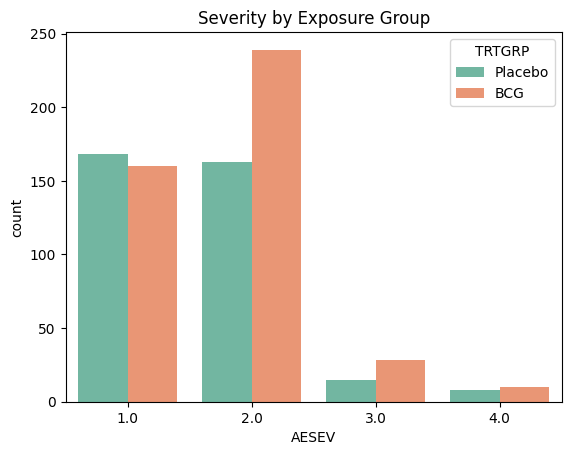

In [15]:
# let's have a look at the data
sns.countplot(x='AESEV', hue='TRTGRP', data=full_data, palette='Set2')
plt.title('Severity by Exposure Group')
plt.show()

In [17]:
group_stats = full_data.groupby('TRTGRP')['AESEV'].describe()
print(group_stats)

         count      mean       std  min  25%  50%  75%  max
TRTGRP                                                     
BCG      437.0  1.743707  0.676091  1.0  1.0  2.0  2.0  4.0
Placebo  354.0  1.612994  0.677398  1.0  1.0  2.0  2.0  4.0


In [19]:
# let's have a look at the data including some demographics information
# first we need to encode the categorical variables
label_encoder = LabelEncoder()
full_data['expect_interact_cat'] = label_encoder.fit_transform(full_data['expect_interact'])
full_data['patients_seen_cat'] = label_encoder.fit_transform(full_data['patients_seen'])
full_data['AESEV'] = full_data['AESEV'].astype(int) # severity should remain ordinal

<ipython-input-19-c31c82e3421b>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  full_data['expect_interact_cat'] = label_encoder.fit_transform(full_data['expect_interact'])
<ipython-input-19-c31c82e3421b>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  full_data['patients_seen_cat'] = label_encoder.fit_transform(full_data['patients_seen'])
<ipython-input-19-c31c82e3421b>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] =

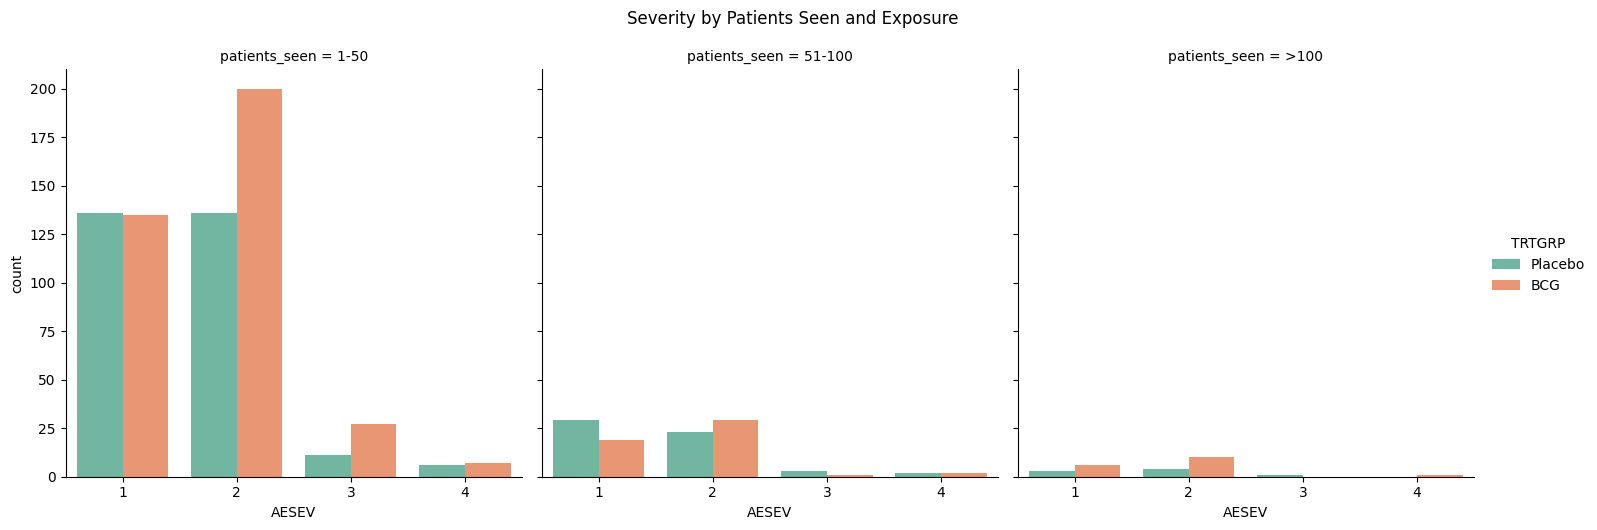

In [20]:
# looking at the severity distribution by patients_seen and expect_interact
sns.catplot(data=full_data, x='AESEV', hue='TRTGRP', col='patients_seen', kind='count', palette='Set2')
plt.suptitle('Severity by Patients Seen and Exposure', y=1.05)
plt.show()

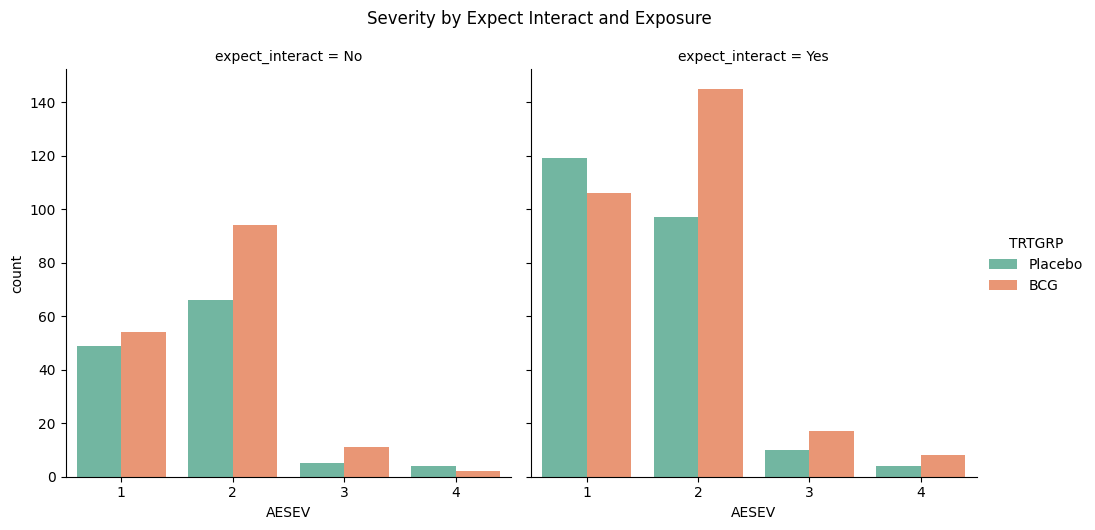

In [21]:
sns.catplot(data=full_data, x='AESEV', hue='TRTGRP', col='expect_interact', kind='count', palette='Set2')
plt.suptitle('Severity by Expect Interact and Exposure', y=1.05)
plt.show()

**Note:** interestingly there do not seem to be many more severe cases even with >100 patients seen by the workers suggesting that the vast majority of workers see 1-50 patients.

Unsurprisingly looking at the number of cases when the worker is expected to interact with the patients we can see this is higher in the 'Yes' subgroup, confirming the initial thinking that the demographics are important to consider as a parameter as they are likely to affect the exposure to disease. Even like this there is a higher count of higher severity in the BCG (vaccine group) which points to our initial hypothesis for the protective effects of the re-vaccination to be False.

To examine statistically the correlation between the groups we can do:

- Chi-square Test: Compares the overall severity distribution between the two groups. Suitable for categorical data with counts/frequencies.

- Mann-Whitney U Test: Tests whether one group tends to have higher/lower severity than the other. Treats severity as ordinal data.

- Effect Size: A rank-biserial correlation quantifies the difference in distributions.

A statistically significant Chi-square test indicates that severity distributions differ while a statistically significant Mann-Whitney U test suggests that one group has systematically higher or lower severity than the other.

In order to consider the demographic parameters we can also perform a:
- Multivariable Analysis: Fit an ordinal logistic regression model to assess the effect of Exposure while adjusting for expect_interract and patients_seen.

In [29]:
# Chi-square tests
for group, group_data in full_data.groupby('expect_interact'):
    print(f"\nChi-square test for expect_interract = {group}")
    severity_table = pd.crosstab(group_data['AESEV'], group_data['TRTGRP'])
    chi2, p, dof, _ = chi2_contingency(severity_table)
    print(f"Chi2={chi2}, p={p}, dof={dof}")


Chi-square test for expect_interract = No
Chi2=3.311692995206908, p=0.3460185104963108, dof=3

Chi-square test for expect_interract = Yes
Chi2=9.31508641975309, p=0.025382121082660535, dof=3


In [30]:
for group, group_data in full_data.groupby('patients_seen'):
    print(f"\nChi-square test for patients_seen = {group}")
    severity_table = pd.crosstab(group_data['AESEV'], group_data['TRTGRP'])
    chi2, p, dof, _ = chi2_contingency(severity_table)
    print(f"Chi2={chi2}, p={p}, dof={dof}")


Chi-square test for patients_seen = 1-50
Chi2=9.420743463606744, p=0.024189637931453605, dof=3

Chi-square test for patients_seen = 51-100
Chi2=3.4529649916646816, p=0.32691383506649596, dof=3

Chi-square test for patients_seen = >100
Chi2=2.6785714285714284, p=0.4438811470106675, dof=3


In [34]:
ae_dm_data.groupby('patients_seen')["USUBJID"].count()
# looking at the number of patients the majority of workers is seeing

,USUBJID
patients_seen,
1-50,835
51-100,129
>100,36


The chi-square test assesses whether there is a significant association between two categorical variables.

In the above two tests we are testing whether the distribution of severity levels is significantly associated with BCG exposure for different groups:
- expect_interact = No and expect_interact = Yes
- number of patients seen: 1-50, 51-100 and >100

Looking at the results we can see that there is a significant association between BCG exposure and severity of COVID-19 only in cases where:
- healthcare workers expected to interact with patients (which makes sense as there is higher exposure to disease)
- healthcare workers which are seeing between 1 and 50 patients (which seems a bit strange but thinking that this would be the majority of workers it makes sense that they would have higher exposure to disease)

In [24]:
# let's encode the vaccination column as well
full_data['TRTGRP_cat'] = full_data['TRTGRP'].map({'Placebo': 0, 'BCG': 1})

<ipython-input-24-6f1fba357c14>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  full_data['TRTGRP_cat'] = full_data['TRTGRP'].map({'Placebo': 0, 'BCG': 1})


In [25]:
# Multivariable Analysis (Ordinal Logistic Regression)
# preparing the ordinal logistic regression model
model = OrderedModel(full_data['AESEV'].astype(int),
                     full_data[['TRTGRP_cat', 'expect_interact_cat', 'patients_seen_cat']].astype(int),
                     distr='logit')

In [26]:
# fitting the model
result = model.fit(method='bfgs')
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.945086
         Iterations: 17
         Function evaluations: 19
         Gradient evaluations: 19
                             OrderedModel Results                             
Dep. Variable:                  AESEV   Log-Likelihood:                -747.56
Model:                   OrderedModel   AIC:                             1507.
Method:            Maximum Likelihood   BIC:                             1535.
Date:                Mon, 13 Jan 2025                                         
Time:                        18:19:34                                         
No. Observations:                 791                                         
Df Residuals:                     785                                         
Df Model:                           3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------

In [27]:
# calculating the odds ratios
odds_ratios = pd.DataFrame({
    "Variable": result.params.index,
    "Odds Ratio": result.params.apply(np.exp),
    "p-value": result.pvalues
})
print("\nOdds Ratios and p-values:")
print(odds_ratios)


Odds Ratios and p-values:
                                Variable  Odds Ratio        p-value
TRTGRP_cat                    TRTGRP_cat    1.524242   2.587392e-03
expect_interact_cat  expect_interact_cat    0.754981   5.163146e-02
patients_seen_cat      patients_seen_cat    1.008515   9.540291e-01
1/2                                  1/2    0.746092   4.036846e-02
2/3                                  2/3    2.859428  4.511194e-107
3/4                                  3/4    1.279274   1.202252e-01


<ipython-input-28-e41668df0d2a>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=odds_ratios, x="Odds Ratio", y="Variable", palette="Set2")


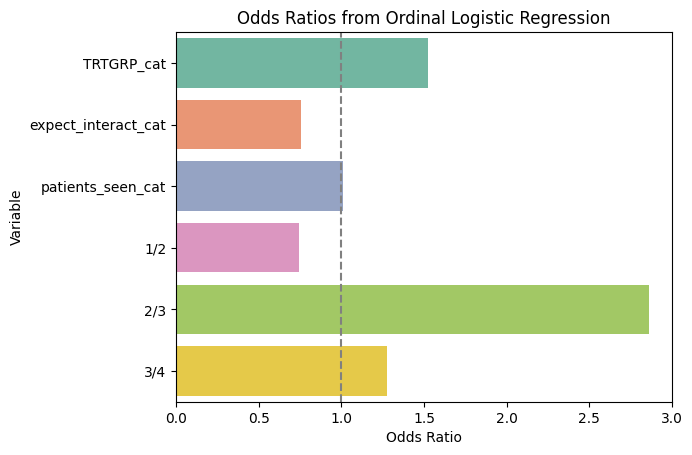

In [28]:
# visualising the odds ratios
sns.barplot(data=odds_ratios, x="Odds Ratio", y="Variable", palette="Set2")
plt.axvline(1, color='gray', linestyle='--')
plt.title("Odds Ratios from Ordinal Logistic Regression")
plt.show()

The coefficients indicate the direction of the relationship between each variable and the severity of COVID-19 (the dependent variable).

- Negative Coefficient: Indicates a lower likelihood of being in a higher severity category (protective effect).
- Positive Coefficient: Indicates a higher likelihood of being in a higher severity category (risk factor).

The odds ratio is the exponential of the coefficient:

- Odds Ratio < 1: Decreased odds of higher severity.
- Odds Ratio > 1: Increased odds of higher severity.

Looking at our results above we can see that
- in TRTGRP_cat (vaccination: Placebo vs. BCG, odds_ratio = 1.524242, p-val = 2.587392e-03) the BCG vaccination **increases** the odds of higher severity compared to placebo by approximately 34.4% and this result is statistically significant, suggesting that the BCG vaccination has the opposite effect and is in fact a risk factor for the healthcare workers and therefore our initial hypothesis is **FALSE**. This is counterintuitive as a result and it might be related to other factors e.g. past medical history of severe diseases or it might be due to reverse labeling of e.g. the AESEV category where 1 is higher severity than 4 but looking at the AE highest score (column AEHS) this doesn't seem to be the case.

- in expect_interact_cat surprisingly healthcare workers expected to interact with patients have approximately 24.5% lower odds of higher severity compared to those not expected to interact (odds_ratio = 0.754981 , p-val = 5.163146e-02), however this result is borderline significant, so the effect may not be strong enough to draw firm conclusions.

### Results

Put results in this section. This includes generating any final plots or calculating any final values, as well as verbose markdown explaining your conclusion based on the interpretation of the results.

In [ ]:
## Put results here

Looking at our results above we can see that
- in TRTGRP_cat (vaccination: Placebo vs. BCG, odds_ratio = 1.524242, p-val = 2.587392e-03) the BCG vaccination **increases** the odds of higher severity compared to placebo by approximately 34.4% and this result is statistically significant, suggesting that the BCG vaccination has the opposite effect and is in fact a risk factor for the healthcare workers and therefore our initial hypothesis is **FALSE**. This is counterintuitive as a result and it might be related to other factors e.g. past medical history of severe diseases or it might be due to reverse labeling of e.g. the AESEV category where 1 is higher severity than 4 but looking at the AE highest score (column AEHS) this doesn't seem to be the case.

- in expect_interact_cat surprisingly healthcare workers expected to interact with patients have approximately 24.5% lower odds of higher severity compared to those not expected to interact (odds_ratio = 0.754981 , p-val = 5.163146e-02), however this result is borderline significant, so the effect may not be strong enough to draw firm conclusions.